In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#!unzip /content/drive/MyDrive/Duke_Dataset/BreastDCEDL_duke/BreastDCEDL_duke/duke_subset_nii/Finetuned_FGT_Mask_v2.zip -d fgt_masks

!unzip /content/drive/MyDrive/Duke_Dataset/BreastDCEDL_duke/BreastDCEDL_duke/duke_subset_nii/Finetuned_Breast_Mask.zip -d breast_masks

In [ ]:
import sys
print(sys.executable)

!{sys.executable} -m pip install nibabel
!{sys.executable} -m pip install pandas
!{sys.executable} -m pip install matplotlib
!{sys.executable} -m pip install numpy
!{sys.executable} -m pip install openpyxl
!{sys.executable} -m pip install pathlib
!{sys.executable} -m pip install --no-cache-dir pyarrow==21.0.0 datasets==4.0.0
!{sys.executable} -m pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118

/usr/bin/python3
Looking in indexes: https://download.pytorch.org/whl/cu118


In [ ]:
from PIL import Image
import requests
import torch
from pathlib import Path
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os
import random as r
import matplotlib.patches as patches
from ipywidgets import interact
import textwrap
import json
from PIL import ImageDraw, ImageFont
import pyarrow
import datasets
import pandas
from datasets import Dataset, DatasetDict


In [ ]:
fgt_mask_dir = '/content/fgt_masks/Finetuned FGT Mask v2'

duke_nifti_folder_path = r'/content/drive/MyDrive/Duke_Dataset/BreastDCEDL_duke/BreastDCEDL_duke/duke_subset_nii/Duke_subset_vol'

post_contrast_paths = []
patient_ids = []
pre_contrast_paths = []
percent_enhancement_1_paths = []

for patient_folder in Path(duke_nifti_folder_path).iterdir():
  #print(patient_folder)
  pid = patient_folder.name
  for subfolder in patient_folder.iterdir():
    if subfolder.name == 'd2n_post.nii.gz':
      post_contrast_paths.append(subfolder) #pc1
    if subfolder.name == 'd2n_pre.nii.gz':
      pre_contrast_paths.append(subfolder) # seg mask
    if subfolder.name == 'pe1.nii.gz':
      percent_enhancement_1_paths.append(subfolder)
  patient_ids.append(pid)

volume_path_df = pd.DataFrame({
    'Patient ID': patient_ids,
    'Post Contrast 1' :post_contrast_paths,
    'Pre Contrast' : pre_contrast_paths,
    'Percent Enhancement 1' : percent_enhancement_1_paths
    })



In [ ]:
breast_mask_path = Path('/content/breast_masks/Finetuned_Breast_Mask')
breast_mask_pid = []
breast_mask_list = []

for bm in breast_mask_path.iterdir():
  breast_mask_pid.append(bm.name[0:14])
  breast_mask_list.append(bm)

bm_path_df = pd.DataFrame({
    'Patient ID': breast_mask_pid,
    'Breast Mask': breast_mask_list
})

In [ ]:
metadata = pd.read_csv(r'/content/drive/MyDrive/Duke_Dataset/BreastDCEDL_duke/BreastDCEDL_duke/duke_subset_nii/Duke_Features/BreastDCEDL_metadata_min_crop.csv')
print(metadata.shape) # all of BreastDECL -> filter for duke only
duke_metadata = metadata[metadata['dataset'] == 'duke']

#duke_metadata.columns
duke_metadata = duke_metadata[['pid','xy_spacing','slice_thick']]

(2070, 29)


In [ ]:
fgt_mask_pid = []
fgt_mask_list = []
for patient_mask in Path(fgt_mask_dir).iterdir():
  fgt_mask_pid.append(patient_mask.name[:14])
  fgt_mask_list.append(patient_mask)

fgt_mask_df = pd.DataFrame({
    'Patient ID': fgt_mask_pid,
    'FGT Mask': fgt_mask_list
})

volume_path_df = volume_path_df.merge(fgt_mask_df)
volume_path_df = volume_path_df.merge(bm_path_df)

volume_path_df=volume_path_df.sort_values('Patient ID')

volume_path_df = volume_path_df.merge(duke_metadata, left_on = 'Patient ID', right_on = 'pid')

volume_path_df


,Patient ID,Post Contrast 1,Pre Contrast,Percent Enhancement 1,FGT Mask,Breast Mask,pid,xy_spacing,slice_thick
0,Breast_MRI_001,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/fgt_masks/Finetuned FGT Mask v2/Breas...,/content/breast_masks/Finetuned_Breast_Mask/Br...,Breast_MRI_001,0.803571,1.1
1,Breast_MRI_002,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/fgt_masks/Finetuned FGT Mask v2/Breas...,/content/breast_masks/Finetuned_Breast_Mask/Br...,Breast_MRI_002,0.585900,1.3
2,Breast_MRI_003,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/fgt_masks/Finetuned FGT Mask v2/Breas...,/content/breast_masks/Finetuned_Breast_Mask/Br...,Breast_MRI_003,0.683600,2.0
3,Breast_MRI_004,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/fgt_masks/Finetuned FGT Mask v2/Breas...,/content/breast_masks/Finetuned_Breast_Mask/Br...,Breast_MRI_004,0.703100,2.0
4,Breast_MRI_005,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/fgt_masks/Finetuned FGT Mask v2/Breas...,/content/breast_masks/Finetuned_Breast_Mask/Br...,Breast_MRI_005,0.781250,2.0
...,...,...,...,...,...,...,...,...,...
194,Breast_MRI_196,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/fgt_masks/Finetuned FGT Mask v2/Breas...,/content/breast_masks/Finetuned_Breast_Mask/Br...,Breast_MRI_196,0.803571,2.0
195,Breast_MRI_197,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/fgt_masks/Finetuned FGT Mask v2/Breas...,/content/breast_masks/Finetuned_Breast_Mask/Br...,Breast_MRI_197,0.758929,1.1
196,Breast_MRI_198,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/fgt_masks/Finetuned FGT Mask v2/Breas...,/content/breast_masks/Finetuned_Breast_Mask/Br...,Breast_MRI_198,0.758929,2.0
197,Breast_MRI_199,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/drive/MyDrive/Duke_Dataset/BreastDCED...,/content/fgt_masks/Finetuned FGT Mask v2/Breas...,/content/breast_masks/Finetuned_Breast_Mask/Br...,Breast_MRI_199,0.664100,1.1


In [ ]:
def CalculateFGTCategory(df,show):
  fgt_category_list = []
  pid_list = []
  fgt_percent_list = []
  for col, row in df.iterrows():
    print(row['Patient ID'])
    pid_list.append(row['Patient ID'])
    #load precontrast, postcontrast, and mask
    fgt_mask_np = np.load(row['FGT Mask'])
    precontrast_nii = nib.load(row['Pre Contrast'])
    precontrast_np = precontrast_nii.get_fdata()
    pc1_nii = nib.load(row['Post Contrast 1'])
    pc1_np = pc1_nii.get_fdata()
    breast_mask_np = np.load(row['Breast Mask'])

    #find whether shapes align
    print(f'FGT Mask Shape: {fgt_mask_np.shape}')
    print(f'Breast Mask Shape {breast_mask_np.shape}')
    print(f'Precontrast Shape: {precontrast_np.shape}')
    print(f'Post Contrast 1 Shape: {pc1_np.shape}')
    class_map = np.argmax(fgt_mask_np, axis=0)
    fgt_mask_bool = (class_map == 2)
    #fgt_mask_bool = (fgt_mask_np > 0.5)
    breast_mask_bool = breast_mask_np>0.5
    t_or_f, counts = np.unique(fgt_mask_bool, return_counts=True)
    print(dict(zip(t_or_f, counts)))
    if show:
      slide = 60 #fgt_mask_np.shape[2]//2
      fig, ax = plt.subplots(3,2,figsize=(8,8))
      ax[0][0].imshow(fgt_mask_np[2][:,:,slide])
      ax[0][1].imshow(fgt_mask_bool[:,:,slide])
      ax[1][0].imshow(breast_mask_np[:,:,slide])
      ax[1][1].imshow(breast_mask_bool[:,:,slide])
      ax[2][0].imshow(precontrast_np[:,:,slide])
      ax[2][1].imshow(pc1_np[:,:,slide])

    #compare precontrast w post contrast voxels
    outside_voxels = np.sum(fgt_mask_bool & ~breast_mask_bool)
    print(f"FGT voxels outside breast mask: {outside_voxels}")

    fgt_mask = fgt_mask_bool & breast_mask_bool # fgt_within_bm

    #get voxel spacing
    #affine = pc1_nii.affine
    #affine_pre = precontrast_nii.affine
    # check_match = affine_pc1 == affine_pre
    # affine_c, af_counts = np.unique(check_match, return_counts=True)
    # print(dict(zip(affine_c, af_counts)))

    # voxel_dims = nib.affines.voxel_sizes(affine)
    # voxel_volume = np.prod(voxel_dims)

    #from Daksh (use metadata):
    voxel_volume = row['xy_spacing'] * row['xy_spacing'] * row['slice_thick']


    fgt_volume = fgt_mask.sum() * voxel_volume
    bm_volume = breast_mask_bool.sum() * voxel_volume
    fgt_percent = (fgt_volume / bm_volume) * 100.0 if bm_volume > 0 else 0.0
    print(f'FGT Percent: {fgt_percent}%')
    fgt_percent_list.append(fgt_percent)
    fgt_category = None
    if fgt_percent < 25:
       fgt_category = "Almost entirely fatty"
    elif fgt_percent < 50:
        fgt_category =  "Scattered areas of fibroglandular density"
    elif fgt_percent < 75:
        fgt_category =  "Heterogeneously dense"
    else:
        fgt_category = "Extremely dense"

    print(f'FGT Category: {fgt_category}')
    fgt_category_list.append(fgt_category)
  return pid_list,fgt_category_list,fgt_percent_list




In [ ]:
pid_list_fgt, fgt_cat_list,fgt_per_list = CalculateFGTCategory(volume_path_df, False) # ask why all FGT precent so low cus rn everything is <25 which is extemely fatty

fgt_df = pd.DataFrame({
    'Patient ID': pid_list_fgt,
    'FGT Categorization': fgt_cat_list,
    'FGT Percentage': fgt_per_list
})

fgt_df

Breast_MRI_001
FGT Mask Shape: (3, 448, 448, 160)
Breast Mask Shape (448, 448, 160)
Precontrast Shape: (448, 448, 160)
Post Contrast 1 Shape: (448, 448, 160)
{np.False_: np.int64(31797145), np.True_: np.int64(315495)}
FGT voxels outside breast mask: 57
FGT Percent: 5.417360428321791%
FGT Category: Almost entirely fatty
Breast_MRI_002
FGT Mask Shape: (3, 512, 512, 142)
Breast Mask Shape (512, 512, 142)
Precontrast Shape: (512, 512, 142)
Post Contrast 1 Shape: (512, 512, 142)
{np.False_: np.int64(36450152), np.True_: np.int64(774296)}
FGT voxels outside breast mask: 6391
FGT Percent: 21.292787368265774%
FGT Category: Almost entirely fatty
Breast_MRI_003
FGT Mask Shape: (3, 512, 512, 156)
Breast Mask Shape (512, 512, 156)
Precontrast Shape: (512, 512, 156)
Post Contrast 1 Shape: (512, 512, 156)
{np.False_: np.int64(40741387), np.True_: np.int64(153077)}
FGT voxels outside breast mask: 1667
FGT Percent: 1.7896498876992035%
FGT Category: Almost entirely fatty
Breast_MRI_004
FGT Mask Shape: 

KeyboardInterrupt: 

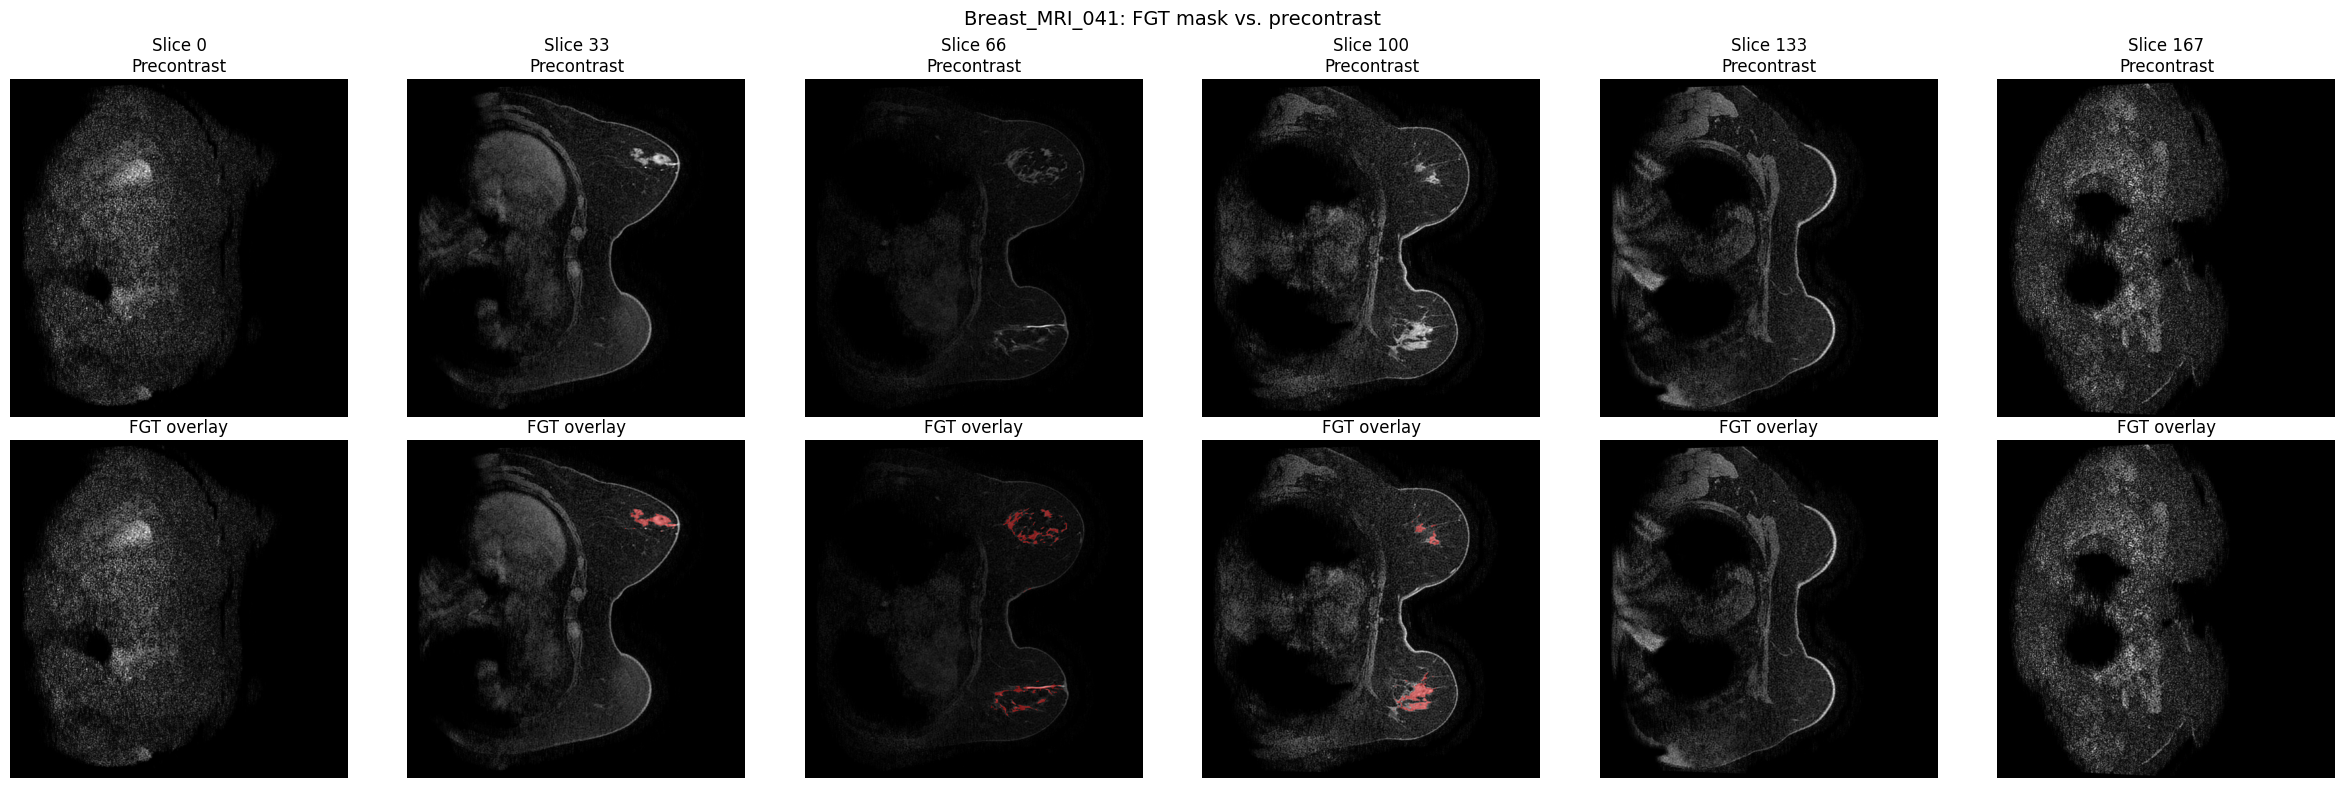

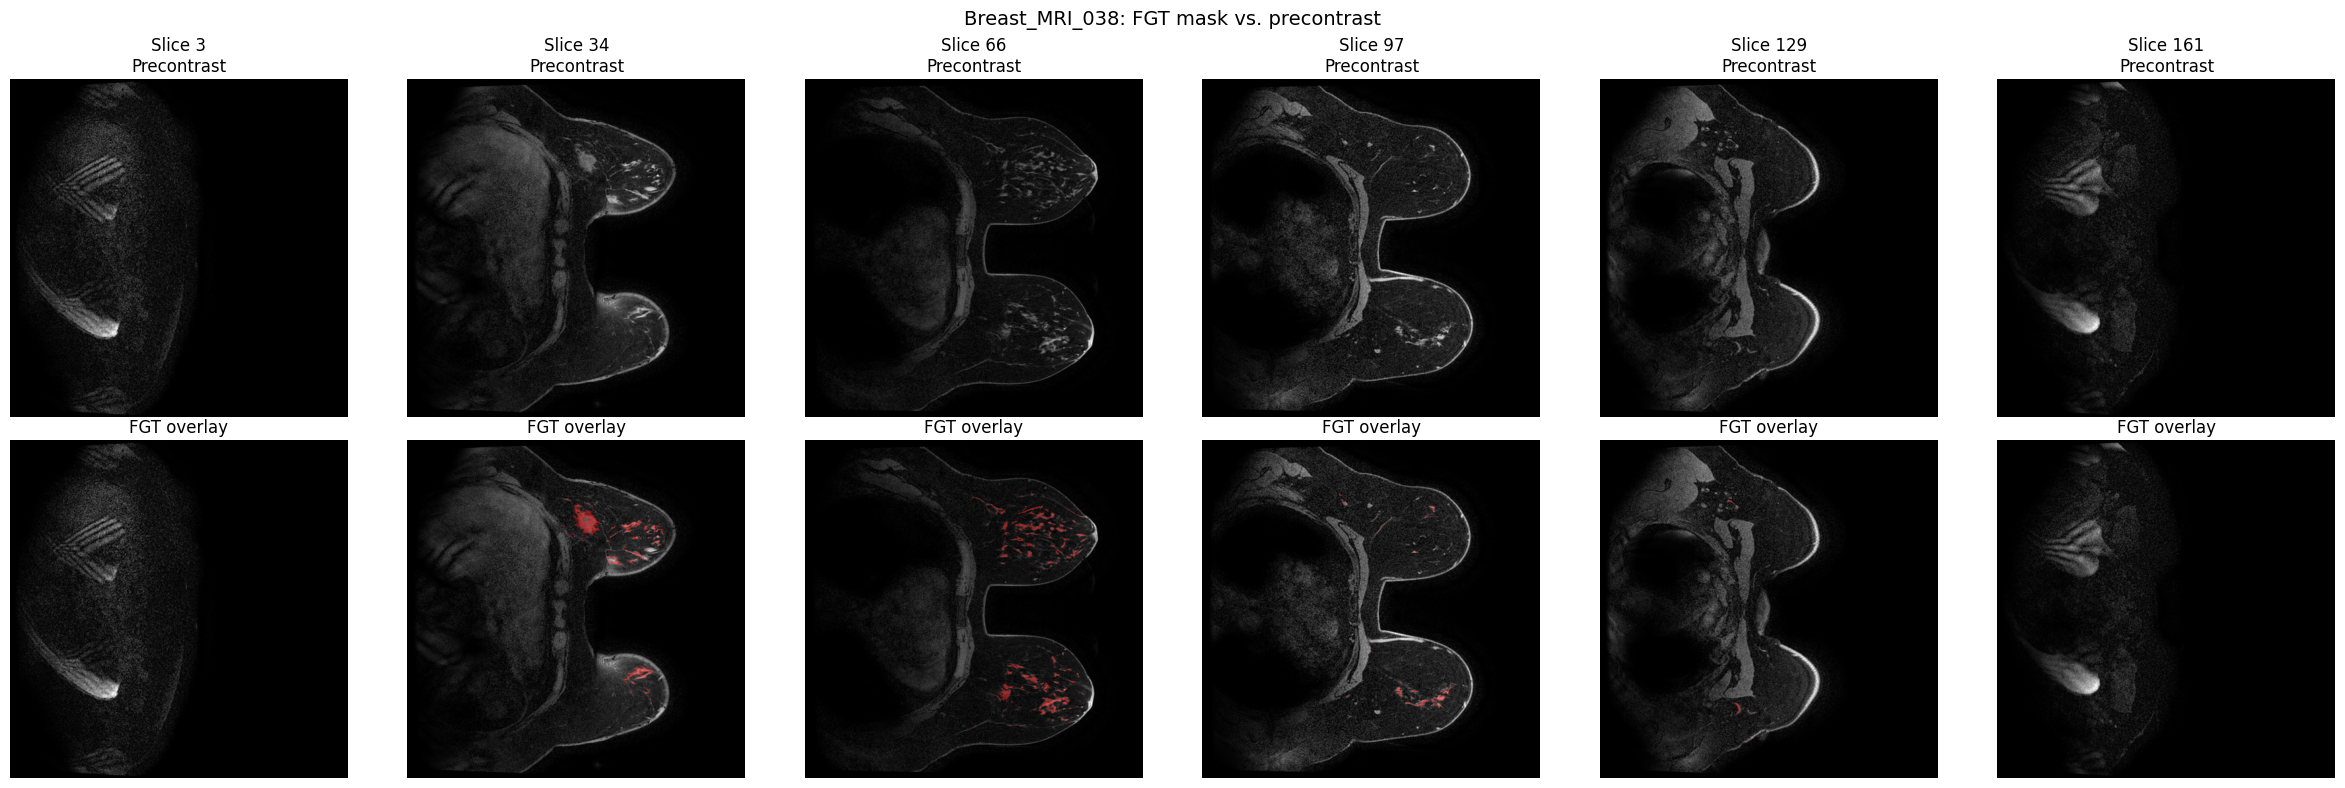

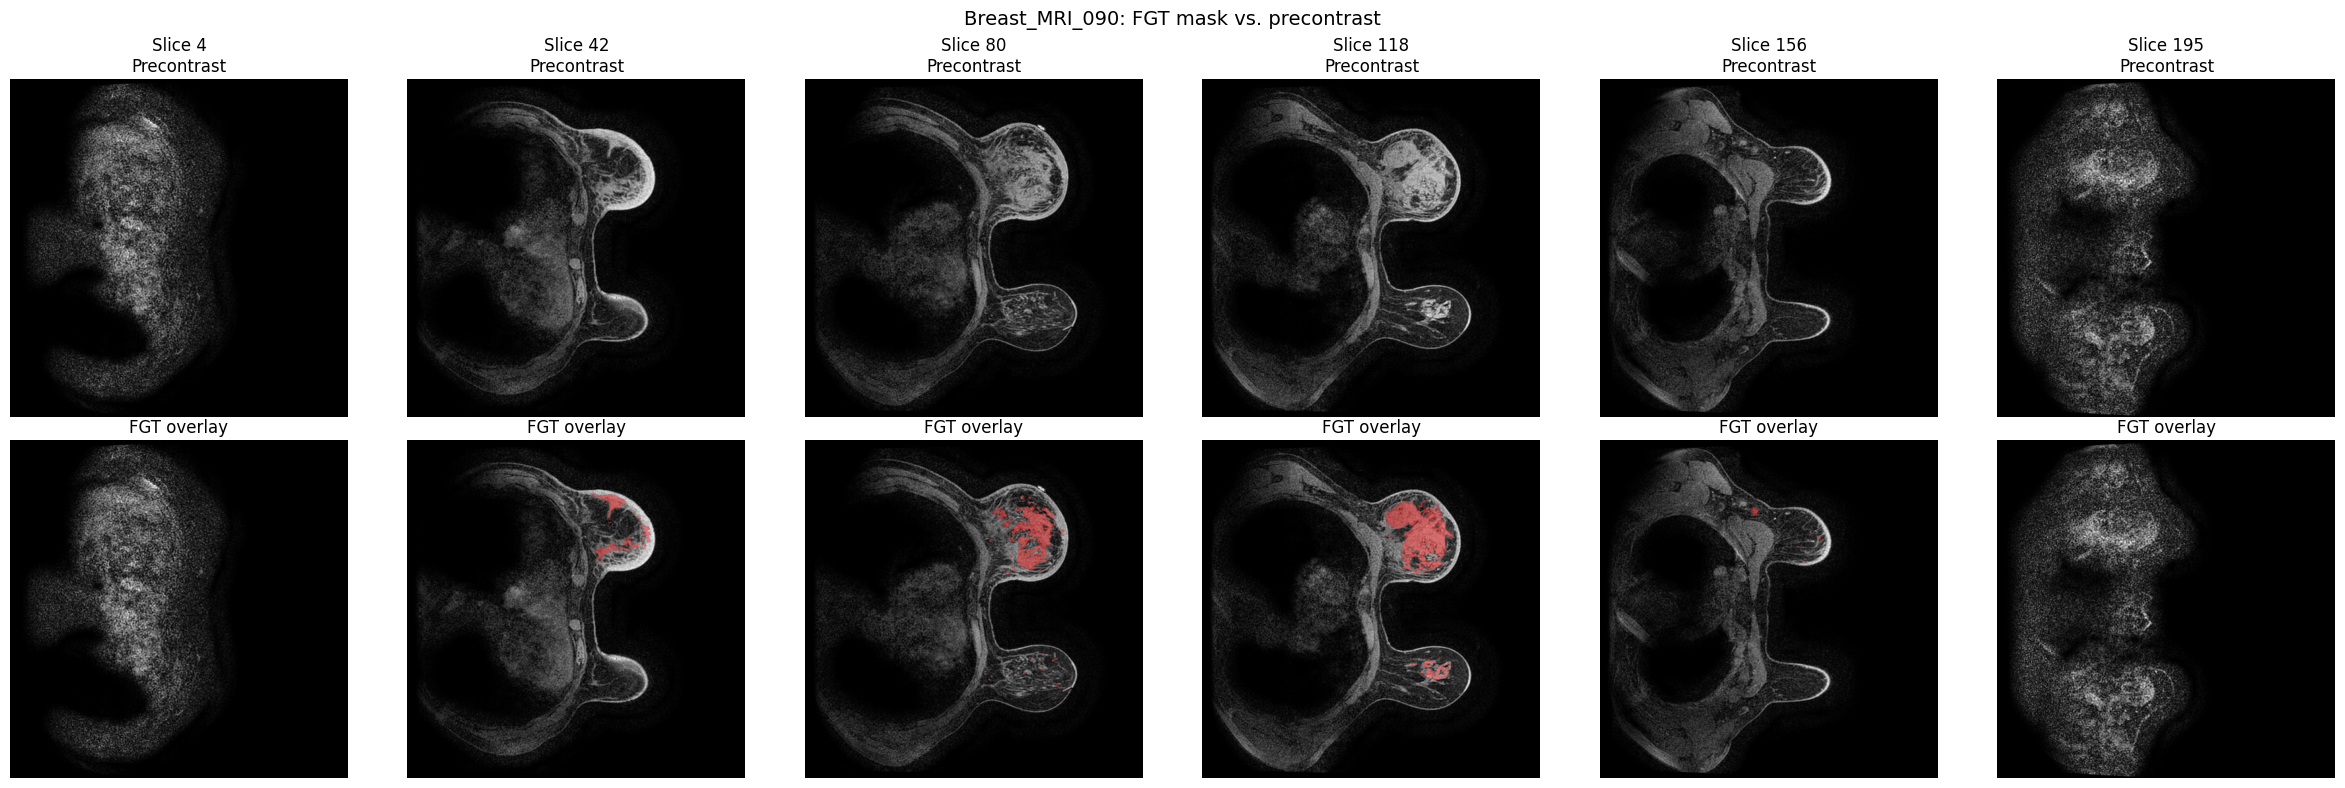

In [ ]:
def FGTOverlay(pre, fgt_mask, breast_mask, patient_id="", n_slices=6, alpha=0.4):
    # Find the z-range for mask
    z_has_content = np.where(breast_mask.any(axis=(0, 1)))[0]
    z_start, z_end = z_has_content.min(), z_has_content.max()

    z_indices = np.linspace(z_start, z_end, n_slices, dtype=int)

    fig, axes = plt.subplots(2, n_slices, figsize=(4 * n_slices, 8))

    for i, z in enumerate(z_indices):
        #precontrast image
        axes[0, i].imshow(pre[:, :, z], cmap='gray')
        axes[0, i].set_title(f'Slice {z}\nPrecontrast')
        axes[0, i].axis('off')

        #precontrast with FGT mask =
        axes[1, i].imshow(pre[:, :, z], cmap='gray')
        masked_fgt = np.ma.masked_where(~fgt_mask[:, :, z], fgt_mask[:, :, z])
        axes[1, i].imshow(masked_fgt, cmap='autumn_r', alpha=alpha, vmin=0, vmax=1)
        axes[1, i].set_title(f'FGT overlay')
        axes[1, i].axis('off')

    fig.suptitle(f'{patient_id}: FGT mask vs. precontrast', fontsize=14)
    plt.tight_layout()
    plt.show()

for i in range(3):
  select_pat_id = f'{np.random.randint(0, 99)}'
  select_pat_id = f"{int(select_pat_id):03d}"

  row = volume_path_df[volume_path_df['pid'] == f'Breast_MRI_{select_pat_id}'].iloc[0]

  raw = np.load(row['FGT Mask'])
  class_map = np.argmax(raw, axis=0)
  fgt_mask = (class_map == 2)

  pre = nib.load(row['Pre Contrast']).get_fdata()
  breast_mask = np.load(row['Breast Mask']) > 0.5

  FGTOverlay(pre, fgt_mask, breast_mask, patient_id=f'Breast_MRI_{select_pat_id}', n_slices=6)

In [ ]:
#BPE Categorization
def PE1PerVox(pre, post, eps=1e-8):
    pre = np.where(pre == 0, eps, pre)  #remove 0
    pe1_ratio = (post - pre) / pre * 100.0
    return pe1_ratio

def GetBPECategory(df):
  pid_list = []
  bpe_percent_list = []
  bpe_category_list = []
  for col, row in df.iterrows():
    print(row['Patient ID'])
    pid_list.append(row['Patient ID'])
    #load precontrast, postcontrast, and mask
    fgt_mask_np = np.load(row['FGT Mask'])
    precontrast_nii = nib.load(row['Pre Contrast'])
    precontrast_np = precontrast_nii.get_fdata()
    pc1_nii = nib.load(row['Post Contrast 1'])
    pc1_np = pc1_nii.get_fdata()
    breast_mask_np = np.load(row['Breast Mask'])

    print(f'FGT Mask Shape: {fgt_mask_np.shape}')
    print(f'Breast Mask Shape {breast_mask_np.shape}')
    print(f'Precontrast Shape: {precontrast_np.shape}')
    print(f'Post Contrast 1 Shape: {pc1_np.shape}')

    class_map = np.argmax(fgt_mask_np, axis=0)
    fgt_mask_bool = (class_map == 2)
    breast_mask_bool = breast_mask_np>0.5

    percent_enhance_np = PE1PerVox(precontrast_np , pc1_np)
    #constrain to within fgt mask
    percent_enhance_in_fgt= np.where(fgt_mask_bool, percent_enhance_np, -np.inf)

    bpe_voxel_mask = percent_enhance_in_fgt > 0.2 # cutoff given in  https://github.com/mazurowski-lab/3D-Breast-FGT-and-Blood-Vessel-Segmentation/blob/main

    #Voxel Volume:
    #from Daksh (use metadata):
    voxel_volume = row['xy_spacing'] * row['xy_spacing'] * row['slice_thick']

    bpe_volume = bpe_voxel_mask.sum() * voxel_volume
    breast_volume = breast_mask_bool.sum() * voxel_volume

    #% of how mich fgt enhanced
    bpe_percent = (bpe_volume / breast_volume) if breast_volume > 0 else 0.0
    bpe_percent_list.append(bpe_percent*100)
    print(f'BPE Percent FGT Enhanced {bpe_percent*100}')
    #catgorize by % threshold again
    bpe_category = None
    if bpe_percent < 25:
       bpe_category = "Minimal"
    elif bpe_percent < 50:
        bpe_category =  "Mild"
    elif bpe_percent < 75:
        bpe_category =  "Moderate"
    else:
        bpe_category = "Marked"

    bpe_category_list.append(bpe_category)
    print(f'BPE Category {bpe_category}')
  return pid_list, bpe_percent_list, bpe_category_list



In [ ]:
pid_bpe, bpe_per, bpe_cat = GetBPECategory(volume_path_df) # similarly its under estimating fgt tissue in relation to bm leading to enhancement lower than accurate categorization

bpe_df = pd.DataFrame({
    'Patient ID': pid_bpe,
    'BPE Categorization': bpe_cat,
    'BPE Percentage of Enhanced FGT': bpe_per
})

fgt_df = fgt_df.merge(bpe_df)

Breast_MRI_001
FGT Mask Shape: (3, 448, 448, 160)
Breast Mask Shape (448, 448, 160)
Precontrast Shape: (448, 448, 160)
Post Contrast 1 Shape: (448, 448, 160)
BPE Percent FGT Enhanced 4.382604364794833
BPE Category Minimal
Breast_MRI_002
FGT Mask Shape: (3, 512, 512, 142)
Breast Mask Shape (512, 512, 142)
Precontrast Shape: (512, 512, 142)
Post Contrast 1 Shape: (512, 512, 142)
BPE Percent FGT Enhanced 14.516379035212035
BPE Category Minimal
Breast_MRI_003
FGT Mask Shape: (3, 512, 512, 156)
Breast Mask Shape (512, 512, 156)
Precontrast Shape: (512, 512, 156)
Post Contrast 1 Shape: (512, 512, 156)
BPE Percent FGT Enhanced 1.6433669010393706
BPE Category Minimal
Breast_MRI_004
FGT Mask Shape: (3, 512, 512, 164)
Breast Mask Shape (512, 512, 164)
Precontrast Shape: (512, 512, 164)
Post Contrast 1 Shape: (512, 512, 164)
BPE Percent FGT Enhanced 1.3867095438933732
BPE Category Minimal
Breast_MRI_005
FGT Mask Shape: (3, 448, 448, 160)
Breast Mask Shape (448, 448, 160)
Precontrast Shape: (448, 

ImageFileError: Cannot work out file type of "/content/drive/MyDrive/Duke_Dataset/BreastDCEDL_duke/BreastDCEDL_duke/duke_subset_nii/Duke_subset_vol/Breast_MRI_100/d2n_pre.nii.gz"

In [ ]:

#fgt_df['FGT Categorization'].value_counts()
if len(fgt_df) >=1000:
  fgt_df.to_csv('FGT_Category.csv', index=False)
  from google.colab import files
  files.download('FGT_Category.csv')